# Customer Churn & Retention Analysis

### IBM Telco Customer Dataset | Python Portfolio Project

**Project Type:** Exploratory Data Analysis (EDA)

**Tools:** Python, Pandas, Seaborn, Matplotlib, Google Colab

**Business Objective:** Identify customer groups associated with higher churn and develop evidence-based retention recommendations.

**Dataset:** IBM Telco Customer Churn — 7,043 customer records.

---

## 1. Data Loading and Exploration


In [10]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the names of all columns
print("\nColumn names:")
print(df.columns.tolist())

# Check the types of data and missing values
print("\nDataset information:")
df.info()


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [12]:
# Convert TotalCharges from text to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate customer records
print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

# Check the updated data type
print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)


Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicate customer IDs:
0

TotalCharges data type:
float64


In [13]:
# Examine customers with missing TotalCharges
missing_customers = df[df["TotalCharges"].isnull()]

# Show their tenure and monthly charges
print(missing_customers[["tenure", "MonthlyCharges", "TotalCharges"]])

# Check whether all missing values belong to new customers
print("\nTenure values for these customers:")
print(missing_customers["tenure"].unique())


      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN

Tenure values for these customers:
[0]


In [14]:
# Replace missing TotalCharges with zero
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check that no missing values remain
print("Total missing values:", df.isnull().sum().sum())

# Confirm the number of customers
print("Total customers:", len(df))

# Check the number of customers who churned
print("\nCustomer churn counts:")
print(df["Churn"].value_counts())

# Calculate the overall churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")

Total missing values: 0
Total customers: 7043

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.54%


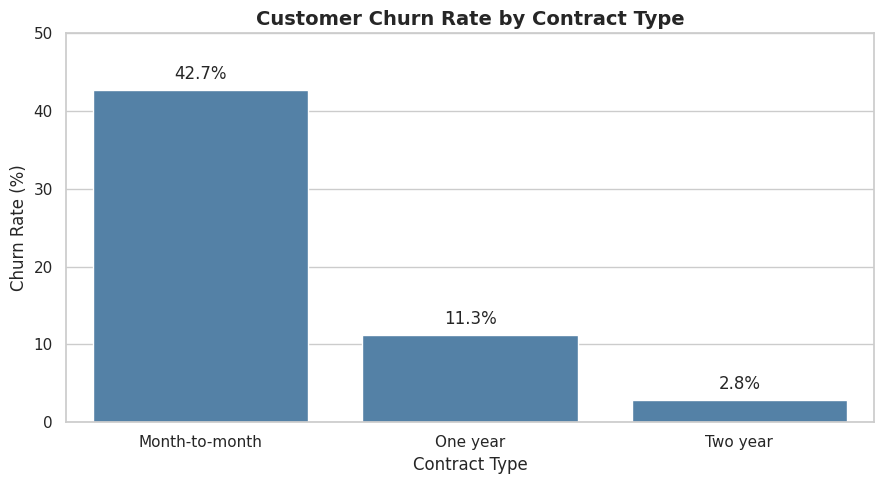

         Contract  Churn Rate
0  Month-to-month   42.709677
1        One year   11.269518
2        Two year    2.831858


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn percentage for each contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Set the chart's appearance
sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

# Create the bar chart
ax = sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn Rate",
    color="steelblue"
)

# Add percentage labels above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Add professional chart labels
plt.title("Customer Churn Rate by Contract Type", fontsize=14, weight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.tight_layout()
plt.show()

# Display exact percentages
print(contract_churn)

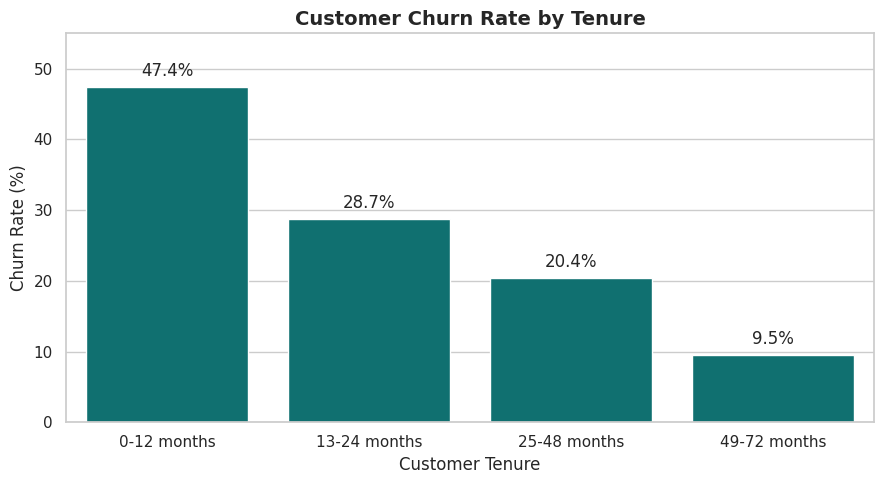

    TenureGroup  Churn Rate
0   0-12 months   47.438243
1  13-24 months   28.710938
2  25-48 months   20.388959
3  49-72 months    9.513176


In [16]:

# Group customers by how long they have stayed
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

# Calculate churn percentage for each group
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Create the chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="Churn Rate",
    color="teal"
)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Format the chart
plt.title("Customer Churn Rate by Tenure", fontsize=14, weight="bold")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)

plt.tight_layout()
plt.show()

# Display the exact results
print(tenure_churn)

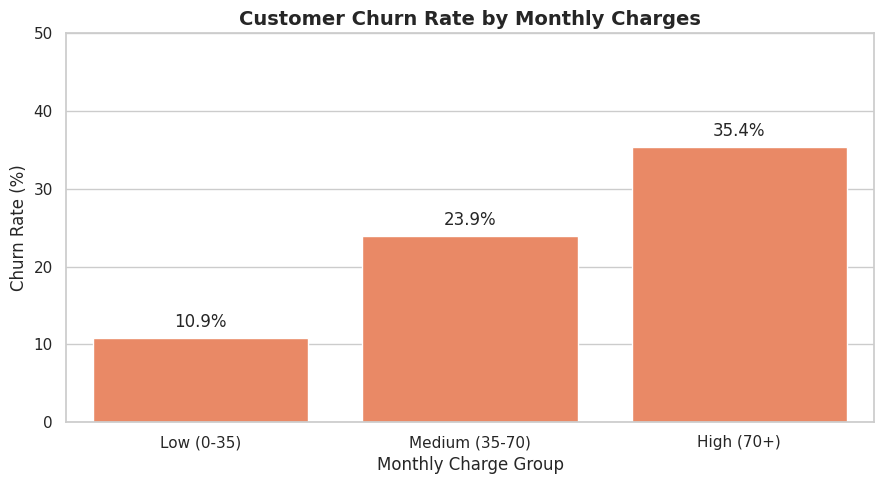

      ChargeGroup  Churn Rate
0      Low (0-35)   10.893372
1  Medium (35-70)   23.942029
2      High (70+)   35.361429


In [17]:
# Create monthly charge groups
df["ChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 120],
    labels=["Low (0-35)", "Medium (35-70)", "High (70+)"]
)

# Calculate churn rate for each price group
charge_churn = (
    df.groupby("ChargeGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Create the chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=charge_churn,
    x="ChargeGroup",
    y="Churn Rate",
    color="coral"
)

# Add percentage labels above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

# Format the chart
plt.title("Customer Churn Rate by Monthly Charges", fontsize=14, weight="bold")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.tight_layout()
plt.show()

# Display the results
print(charge_churn)


Business Insights & Retention Recommendations

Executive Summary

This project analysed 7,043 telecommunications customer records to identify patterns associated with customer churn.

The overall customer churn rate was 26.54%, representing 1,869 customers who left the company.

Three important patterns emerged relating to contract type, customer tenure and monthly charges.

Recommendation 1: Encourage Longer-Term Contracts

Finding: Month-to-month customers had a churn rate of 42.7%, compared with just 2.8% for customers on two-year contracts.

Recommendation: Investigate incentives for month-to-month customers to move to longer-term contracts, such as loyalty discounts, additional services or flexible upgrade options.

Business value: Improving retention among month-to-month customers could reduce customer turnover and protect recurring revenue.

Recommendation 2: Improve First-Year Customer Retention

Finding: Customers with 0–12 months of tenure had a churn rate of 47.4%, compared with 9.5% among customers with 49–72 months of tenure.

Recommendation: Introduce a structured customer onboarding programme, including welcome communications, proactive support and satisfaction check-ins during the first year.

Business value: Improving the early customer experience could reduce customer losses and increase customer lifetime value.

Recommendation 3: Investigate Pricing and Perceived Value

Finding: Customers in the highest monthly charge group had a churn rate of 35.4%, compared with 10.9% in the lowest group.

Recommendation: Review the value offered to higher-paying customers, investigate satisfaction levels and test targeted retention offers.

Business value: Addressing potential value-for-money concerns could help retain customers who contribute substantial monthly revenue.

Limitations

These findings show associations rather than cause-and-effect relationships. Contract type, tenure and monthly charges may also be related to other customer characteristics.

The dataset is observational, so the recommendations should be tested before company-wide implementation.

Conclusion

The analysis highlights three potential priorities for customer retention: contract flexibility, early customer engagement and perceived service value.

These findings provide a foundation for further investigation and targeted retention strategies.